In [1]:
print ("hello machine learning")

hello machine learning


In [2]:
!pip install numpy pandas matplotlib seaborn scikit-learn

In [3]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("creditcard.csv")

# Display first 5 rows
print(df.head())

# Dataset shape
print(df.shape)

# Dataset information
print(df.info())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [7]:
# Check fraud and genuine counts
print(df["Class"].value_counts())

# Check missing values
print(df.isnull().sum().sum())

# Check duplicate records
print(df.duplicated().sum())

# Check fraud percentage
print(df["Class"].value_counts(normalize=True) * 100)

Class
0.0    174056
1.0       361
Name: count, dtype: int64
15
661


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

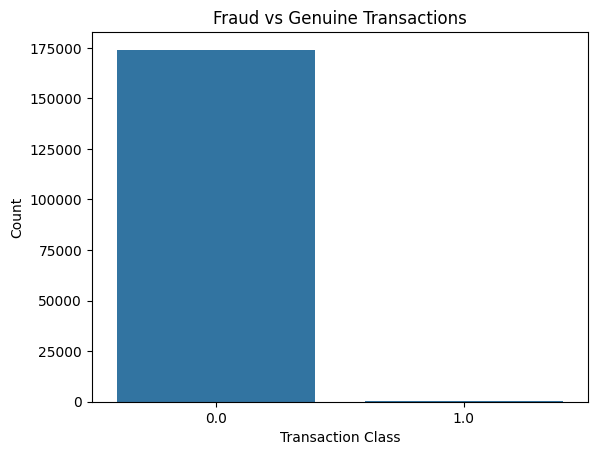

In [10]:
sns.countplot(data=df, x="Class")

plt.title("Fraud vs Genuine Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Count")

plt.show()

In [11]:
print("Missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values: 15
Duplicate rows: 661


In [12]:
df[df.duplicated(keep=False)].head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0.0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0.0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0.0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0.0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0.0


In [13]:
df = df.drop_duplicates().copy()

print(df.shape)

(173757, 31)


In [14]:
X = df.drop("Class", axis=1)

y = df["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (173757, 30)
Target: (173757,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print(X_train.shape)
print(X_test.shape)

ValueError: Input y contains NaN.

In [17]:
print(df.shape)
print(df["Class"].isnull().sum())
print(df["Class"].value_counts(dropna=False))

(173757, 31)
1
Class
0.0    173413
1.0       343
NaN         1
Name: count, dtype: int64


In [18]:
df = df.dropna(subset=["Class"]).copy()

print(df.shape)
print(df["Class"].isnull().sum())

(173756, 31)
0


In [19]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Fraud in train:", y_train.sum())
print("Fraud in test:", y_test.sum())

X_train: (139004, 30)
X_test: (34752, 30)
Fraud in train: 274.0
Fraud in test: 69.0


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[["Amount", "Time"]] = scaler.fit_transform(
    X_train[["Amount", "Time"]]
)

X_test[["Amount", "Time"]] = scaler.transform(
    X_test[["Amount", "Time"]]
)

In [22]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train,
    y_train
)

print(y_train_ros.value_counts())

Class
0.0    138730
1.0    138730
Name: count, dtype: int64


In [23]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print(y_train_smote.value_counts())

Class
0.0    138730
1.0    138730
Name: count, dtype: int64


In [24]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [25]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_lr.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [26]:
y_pred = model_lr.predict(X_test)

print(y_pred[:10])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [27]:
y_prob = model_lr.predict_proba(X_test)

print(y_prob[:5])

[[0.97412474 0.02587526]
 [0.9673671  0.0326329 ]
 [0.92238793 0.07761207]
 [0.77339425 0.22660575]
 [0.97852303 0.02147697]]


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9786774861878453
Precision: 0.08
Recall: 0.927536231884058
F1 Score: 0.1472957422324511
[[33947   736]
 [    5    64]]
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99     34683
         1.0       0.08      0.93      0.15        69

    accuracy                           0.98     34752
   macro avg       0.54      0.95      0.57     34752
weighted avg       1.00      0.98      0.99     34752



In [29]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=5,
    random_state=42
)

model_dt.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)

In [30]:
y_pred_dt = model_dt.predict(X_test)

print(y_pred_dt[:10])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("Precision:", precision_score(
    y_test, y_pred_dt, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred_dt, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred_dt, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print(classification_report(
    y_test, y_pred_dt, zero_division=0
))

Accuracy: 0.975166896869245
Precision: 0.0665938864628821
Recall: 0.8840579710144928
F1 Score: 0.12385786802030457
Confusion Matrix:
[[33828   855]
 [    8    61]]
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99     34683
         1.0       0.07      0.88      0.12        69

    accuracy                           0.98     34752
   macro avg       0.53      0.93      0.56     34752
weighted avg       1.00      0.98      0.99     34752



In [32]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_jobs=-1,
                       random_state=42)

In [33]:
y_pred_rf = model_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.9993093922651933
Precision: 0.835820895522388
Recall: 0.8115942028985508
F1 Score: 0.8235294117647058
Confusion Matrix:
[[34672    11]
 [   13    56]]


In [34]:
!pip install xgboost

In [35]:
from xgboost import XGBClassifier
scale_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print(scale_weight)

506.3138686131387


In [36]:
model_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [37]:
y_pred_xgb = model_xgb.predict(X_test)

In [38]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

print("Precision:", precision_score(
    y_test, y_pred_xgb, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred_xgb, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred_xgb, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy: 0.9991942909760589
Precision: 0.7411764705882353
Recall: 0.9130434782608695
F1 Score: 0.8181818181818182
Confusion Matrix:
[[34661    22]
 [    6    63]]


In [39]:
!pip install lightgbm

In [40]:
from lightgbm import LGBMClassifier

In [41]:
model_lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

model_lgbm.fit(X_train, y_train)

LGBMClassifier(class_weight='balanced', learning_rate=0.05, max_depth=5,
               n_estimators=300, n_jobs=-1, num_leaves=15, random_state=42,
               verbosity=-1)

In [43]:
y_pred_lgbm = model_lgbm.predict(X_test)

In [44]:
print("Accuracy:", accuracy_score(y_test, y_pred_lgbm))

print("Precision:", precision_score(
    y_test, y_pred_lgbm, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred_lgbm, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred_lgbm, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lgbm))

Accuracy: 0.999338167587477
Precision: 0.8108108108108109
Recall: 0.8695652173913043
F1 Score: 0.8391608391608392
Confusion Matrix:
[[34669    14]
 [    9    60]]


In [45]:
from sklearn.metrics import average_precision_score

models = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "Random Forest": model_rf,
    "XGBoost": model_xgb,
    "LightGBM": model_lgbm
}

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    pr_auc = average_precision_score(y_test, y_prob)

    print(name, "PR-AUC:", round(pr_auc, 4))


Logistic Regression PR-AUC: 0.7186
Decision Tree PR-AUC: 0.4975
Random Forest PR-AUC: 0.8656
XGBoost PR-AUC: 0.8648
LightGBM PR-AUC: 0.8431


In [46]:
from sklearn.model_selection import train_test_split

X_sub_train, X_val, y_sub_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [47]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf_tune = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_tune.fit(X_sub_train, y_sub_train)

scale_weight = (
    (y_sub_train == 0).sum() /
    (y_sub_train == 1).sum()
)

xgb_tune = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_tune.fit(X_sub_train, y_sub_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [48]:
import numpy as np
from sklearn.metrics import (
    precision_recall_curve,
    classification_report
)

for name, model in {
    "Random Forest": rf_tune,
    "XGBoost": xgb_tune
}.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, y_prob
    )

    # Minimum 90% recall achieve panna thresholds
    valid = np.where(recall[:-1] >= 0.90)[0]

    if len(valid) == 0:
        print(name, "No threshold achieved 90% recall")
        continue

    best_idx = valid[np.argmax(precision[valid])]
    best_threshold = thresholds[best_idx]

    y_pred = (y_prob >= best_threshold).astype(int)

    print("\n", name)
    print("Best threshold:", best_threshold)
    print(classification_report(y_val, y_pred))


 Random Forest
Best threshold: 0.027037761047022612
              precision    recall  f1-score   support

         0.0       1.00      0.97      0.98     27746
         1.0       0.06      0.93      0.11        55

    accuracy                           0.97     27801
   macro avg       0.53      0.95      0.55     27801
weighted avg       1.00      0.97      0.98     27801


 XGBoost
Best threshold: 0.035286862
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     27746
         1.0       0.28      0.91      0.43        55

    accuracy                           1.00     27801
   macro avg       0.64      0.95      0.72     27801
weighted avg       1.00      1.00      1.00     27801



In [49]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier

scale_weight = (
    (y_sub_train == 0).sum() /
    (y_sub_train == 1).sum()
)

xgb_base = XGBClassifier(
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.02, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_sub_train, y_sub_train)

print("Best Parameters:")
print(random_search.best_params_)

print("Best CV PR-AUC:")
print(random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}
Best CV PR-AUC:
0.8714936082227058


In [50]:
best_xgb = random_search.best_estimator_

print("Best CV PR-AUC:", random_search.best_score_)

Best CV PR-AUC: 0.8714936082227058


In [51]:
from sklearn.metrics import (
    average_precision_score,
    classification_report
)

val_prob = best_xgb.predict_proba(X_val)[:, 1]

print(
    "Validation PR-AUC:",
    average_precision_score(y_val, val_prob)
)

Validation PR-AUC: 0.8690421555632607


In [52]:
!pip install shap

In [53]:
import shap

explainer = shap.TreeExplainer(best_xgb)

shap_values = explainer.shap_values(X_val)

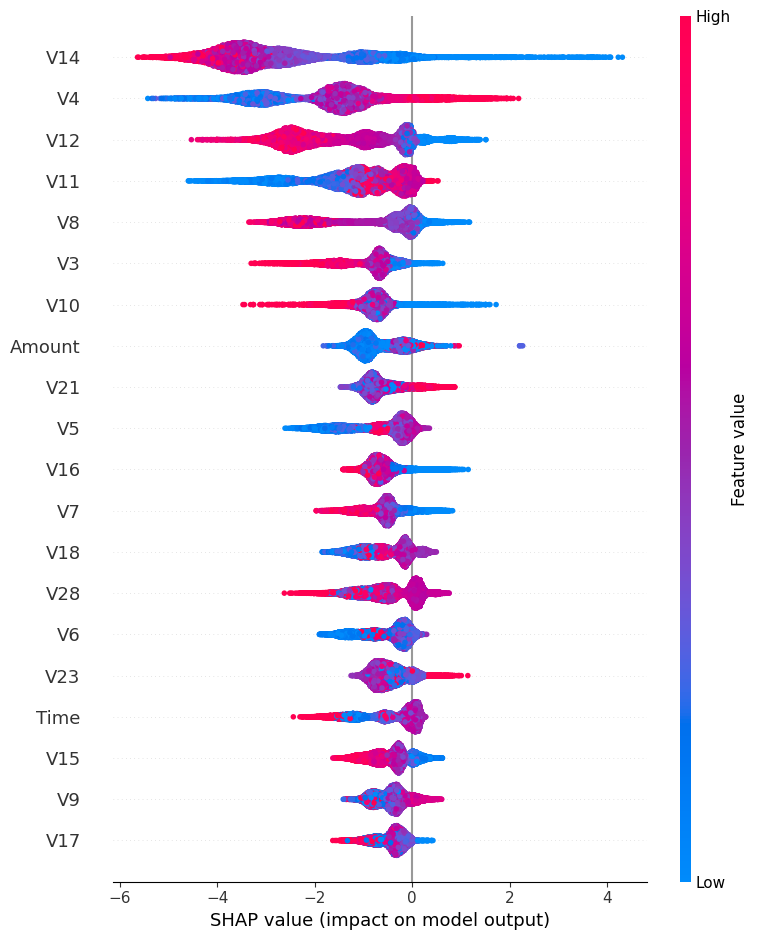

In [54]:
shap.summary_plot(shap_values, X_val)

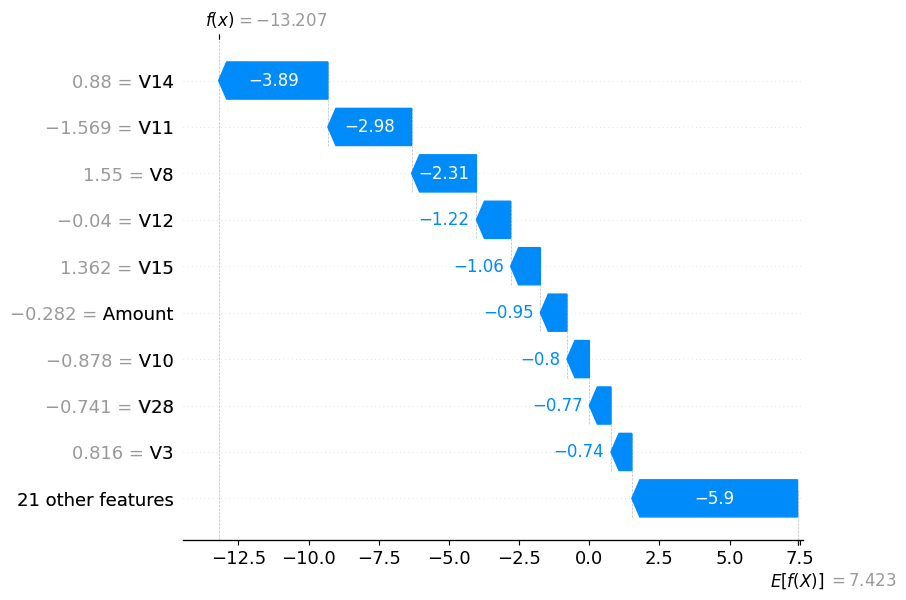

In [55]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_val.iloc[0].values,
        feature_names=X_val.columns.tolist()
    )
)

In [56]:
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

models = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "Random Forest": model_rf,
    "XGBoost": model_xgb,
    "LightGBM": model_lgbm,
    "Tuned XGBoost": best_xgb
}

results = []

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    # Use 0.5 for baseline models;
    # tuned XGBoost uses validation-selected threshold
    threshold = best_threshold if name == "Tuned XGBoost" else 0.5

    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_test, y_pred)
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.sort_values("PR-AUC", ascending=False))

                 Model    PR-AUC  Precision    Recall  F1-Score  Accuracy
5        Tuned XGBoost  0.879192   0.789474  0.869565  0.827586  0.999281
2        Random Forest  0.865577   0.835821  0.811594  0.823529  0.999309
3              XGBoost  0.864778   0.741176  0.913043  0.818182  0.999194
4             LightGBM  0.843062   0.810811  0.869565  0.839161  0.999338
0  Logistic Regression  0.718563   0.080000  0.927536  0.147296  0.978677
1        Decision Tree  0.497462   0.066594  0.884058  0.123858  0.975167
